In [3]:
!pip install -q -U ultralytics


import torch
from pathlib import Path
from ultralytics import YOLO

# Your manually uploaded checkpoint
WEIGHTS_PATH = "/content/best.pt"

assert Path(WEIGHTS_PATH).exists(), (
    "best.pt not found. Upload it using the Colab Files panel."
)

model = YOLO(WEIGHTS_PATH)

print("YOLO26m loaded successfully!")
print("Weights:", WEIGHTS_PATH)

YOLO26m loaded successfully!
Weights: /content/best.pt


In [4]:
from google.colab import drive
from pathlib import Path
import zipfile

drive.mount('/content/drive')

# Locate your ZIP in MyDrive
zip_matches = list(
    Path("/content/drive/MyDrive").rglob("SHWD_960_YOLO_DETR.zip")
)

assert len(zip_matches) > 0, "Dataset ZIP not found in Google Drive."

ZIP_PATH = zip_matches[0]

print("ZIP found:", ZIP_PATH)

# Extract
EXTRACT_PATH = Path("/content/SHWD_Extracted")
EXTRACT_PATH.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, 'r') as z:
    z.extractall(EXTRACT_PATH)

# Locate the actual preprocessed dataset root
yaml_matches = list(EXTRACT_PATH.rglob("data.yaml"))

assert len(yaml_matches) > 0, "data.yaml not found after extraction."

DATASET_PATH = yaml_matches[0].parent

print("Dataset loaded:", DATASET_PATH)
print("Train images:", len(list((DATASET_PATH / "images/train").glob("*"))))
print("Validation images:", len(list((DATASET_PATH / "images/val").glob("*"))))
print("Test images:", len(list((DATASET_PATH / "images/test").glob("*"))))

Mounted at /content/drive
ZIP found: /content/drive/MyDrive/SHWD_960_YOLO_DETR.zip
Dataset loaded: /content/SHWD_Extracted/SHWD_960_Preprocessed
Train images: 5457
Validation images: 607
Test images: 1517


In [7]:

# ============================================================
# YOLO26m — ONLINE CONTRAST + THIN GRID OCCLUSION
# 20 EPOCHS | 90% OBJECT-COVERAGE REMOVAL THRESHOLD
# ============================================================

import os
import sys
import random
import zipfile
import importlib
from pathlib import Path

import numpy as np
import yaml
import albumentations as A

from google.colab import drive
from ultralytics import YOLO

# ============================================================
# 1. MOUNT GOOGLE DRIVE
# ============================================================

drive.mount("/content/drive")

# ============================================================
# 2. LOAD YOLO26m CHECKPOINT
# ============================================================

WEIGHTS_PATH = Path("/content/best.pt")

assert WEIGHTS_PATH.exists(), (
    "best.pt not found. Upload it through the Colab Files panel."
)

model = YOLO(str(WEIGHTS_PATH))

print("YOLO26m checkpoint loaded.")

# ============================================================
# 3. FIND AND EXTRACT DATASET ZIP
# ============================================================

ZIP_NAME = "SHWD_960_YOLO_DETR.zip"

zip_candidates = list(
    Path("/content/drive/MyDrive").rglob(ZIP_NAME)
)

assert zip_candidates, "Dataset ZIP not found in Google Drive."

ZIP_PATH = zip_candidates[0]

EXTRACT_PATH = Path("/content/SHWD_Extracted")
EXTRACT_PATH.mkdir(parents=True, exist_ok=True)

print("Extracting dataset...")

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(EXTRACT_PATH)

yaml_files = list(EXTRACT_PATH.rglob("data.yaml"))

assert yaml_files, "data.yaml not found inside ZIP."

DATASET_PATH = yaml_files[0].parent

for folder in [
    "images/train",
    "images/val",
    "images/test",
    "labels/train"
]:
    assert (DATASET_PATH / folder).exists(), (
        f"Missing dataset folder: {folder}"
    )

print("Dataset:", DATASET_PATH)
print("Training images:", len(list((DATASET_PATH / "images/train").glob("*"))))
print("Validation images:", len(list((DATASET_PATH / "images/val").glob("*"))))
print("Test images:", len(list((DATASET_PATH / "images/test").glob("*"))))

# ============================================================
# 4. CREATE IMPORTABLE CUSTOM DUAL TRANSFORM
# ============================================================

# DualTransform processes both images and bounding boxes.
# Objects covered by MORE THAN 90% are removed from labels.
# All other boxes remain unchanged.

MODULE_CODE = r'''
import numpy as np
import albumentations as A


class ThinGridOcclusion(A.DualTransform):

    def __init__(
        self,
        spacing=(80, 140),
        thickness=(5, 12),
        removal_threshold=0.90,
        p=0.40
    ):
        super().__init__(p=p)

        self.spacing = spacing
        self.thickness = thickness
        self.removal_threshold = removal_threshold

    def get_params_dependent_on_data(self, params, data):

        height, width = params["shape"][:2]

        return {
            "spacing_x": self.py_random.randint(
                self.spacing[0], self.spacing[1]
            ),
            "spacing_y": self.py_random.randint(
                self.spacing[0], self.spacing[1]
            ),
            "thickness": self.py_random.randint(
                self.thickness[0], self.thickness[1]
            ),
            "offset_x": self.py_random.random(),
            "offset_y": self.py_random.random(),
            "shift_x": self.py_random.random(),
            "shift_y": self.py_random.random(),
            "height": height,
            "width": width
        }

    @staticmethod
    def make_mask(
        height, width,
        spacing_x, spacing_y,
        thickness, offset_x, offset_y
    ):

        mask = np.zeros((height, width), dtype=bool)

        ox = int(offset_x * spacing_x)
        oy = int(offset_y * spacing_y)

        # Vertical strips
        for x in range(ox, width, spacing_x):

            x1 = max(0, x - thickness // 2)
            x2 = min(width, x1 + thickness)

            mask[:, x1:x2] = True

        # Horizontal strips
        for y in range(oy, height, spacing_y):

            y1 = max(0, y - thickness // 2)
            y2 = min(height, y1 + thickness)

            mask[y1:y2, :] = True

        return mask

    def apply(
        self,
        image,
        spacing_x=100,
        spacing_y=100,
        thickness=6,
        offset_x=0.5,
        offset_y=0.5,
        shift_x=0.5,
        shift_y=0.5,
        height=None,
        width=None,
        **params
    ):

        height, width = image.shape[:2]

        mask = self.make_mask(
            height, width,
            spacing_x, spacing_y,
            thickness, offset_x, offset_y
        )

        # Fill grid with pixels sampled from shifted image.
        sx = max(1, int(shift_x * 12) + 1)
        sy = max(1, int(shift_y * 12) + 1)

        yy = np.clip(
            np.arange(height) + sy, 0, height - 1
        )
        xx = np.clip(
            np.arange(width) + sx, 0, width - 1
        )

        shifted = image[yy[:, None], xx[None, :]]

        output = image.copy()
        output[mask] = shifted[mask]

        return output

    def apply_to_bboxes(
        self,
        bboxes,
        spacing_x=100,
        spacing_y=100,
        thickness=6,
        offset_x=0.5,
        offset_y=0.5,
        height=None,
        width=None,
        **params
    ):

        if len(bboxes) == 0:
            return bboxes

        height = int(height)
        width = int(width)

        mask = self.make_mask(
            height, width,
            spacing_x, spacing_y,
            thickness, offset_x, offset_y
        )

        bboxes = np.asarray(bboxes)
        keep = []

        for box in bboxes:

            # Albumentations bbox format: normalized xyxy.
            x1 = int(np.floor(box[0] * width))
            y1 = int(np.floor(box[1] * height))
            x2 = int(np.ceil(box[2] * width))
            y2 = int(np.ceil(box[3] * height))

            x1 = np.clip(x1, 0, width)
            x2 = np.clip(x2, 0, width)
            y1 = np.clip(y1, 0, height)
            y2 = np.clip(y2, 0, height)

            if x2 <= x1 or y2 <= y1:
                keep.append(False)
                continue

            object_mask = mask[y1:y2, x1:x2]

            coverage = float(object_mask.mean())

            # Remove annotation only when coverage exceeds 90%.
            keep.append(coverage <= self.removal_threshold)

        return bboxes[np.asarray(keep, dtype=bool)]

    def get_transform_init_args_names(self):
        return (
            "spacing",
            "thickness",
            "removal_threshold"
        )
'''

MODULE_PATH = Path("/content/thin_grid_augmentation.py")
MODULE_PATH.write_text(MODULE_CODE)

if "/content" not in sys.path:
    sys.path.insert(0, "/content")

importlib.invalidate_caches()

import thin_grid_augmentation

ThinGridOcclusion = thin_grid_augmentation.ThinGridOcclusion

# ============================================================
# 5. DEFINE ONLINE AUGMENTATION
# ============================================================

custom_augmentations = [

    # Contrast variation
    A.RandomBrightnessContrast(
        brightness_limit=0.0,
        contrast_limit=0.25,
        p=0.70
    ),

    # Occasional grayscale
    A.ToGray(p=0.10),

    # Random connected thin grid
    ThinGridOcclusion(
        spacing=(80, 140),
        thickness=(5, 12),
        removal_threshold=0.90,
        p=0.40
    )
]

# Verify that Ultralytics can serialize the transforms.
serialized = A.to_dict(
    A.Compose(custom_augmentations)
)

print("Augmentation serialization check passed.")

# ============================================================
# 6. CREATE TRAINING YAML
# ============================================================

NEW_YAML = DATASET_PATH / "data_online_augmented.yaml"

yaml_content = {
    "path": str(DATASET_PATH),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": {
        0: "hat",
        1: "person"
    }
}

with open(NEW_YAML, "w") as f:
    yaml.safe_dump(yaml_content, f, sort_keys=False)

print("Training YAML:", NEW_YAML)

# ============================================================
# 7. FINE-TUNE YOLO26m
# ============================================================

results = model.train(

    data=str(NEW_YAML),

    epochs=20,
    patience=10,

    imgsz=960,
    batch=5,
    device=0,
    workers=2,

    # Class imbalance
    cls_pw=0.5,

    # Existing colour augmentation
    hsv_h=0.015,
    hsv_s=0.7,
    hsv_v=0.4,

    # Existing geometric augmentation
    degrees=5.0,
    translate=0.1,
    scale=0.5,
    fliplr=0.5,
    flipud=0.0,

    # Existing image mixing
    mosaic=1.0,
    mixup=0.1,
    close_mosaic=10,

    # Custom online augmentation
    augmentations=custom_augmentations,

    # Stability
    amp=True,
    seed=42,
    deterministic=True,

    # Save directly to Drive
    project="/content/drive/MyDrive/SHWD_Experiments",
    name="YOLO26m_Contrast_ThinGrid_Online",
    exist_ok=False,

    save=True,
    plots=True
)

# ============================================================
# 8. VERIFY CHECKPOINTS
# ============================================================

SAVE_DIR = Path(results.save_dir)

BEST_PATH = SAVE_DIR / "weights/best.pt"
LAST_PATH = SAVE_DIR / "weights/last.pt"

print("\nTRAINING COMPLETE")
print("Best checkpoint:", BEST_PATH)
print("Best exists:", BEST_PATH.exists())
print("Last checkpoint:", LAST_PATH)
print("Last exists:", LAST_PATH.exists())


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
YOLO26m checkpoint loaded.
Extracting dataset...
Dataset: /content/SHWD_Extracted/SHWD_960_Preprocessed
Training images: 5457
Validation images: 607
Test images: 1517
Augmentation serialization check passed.
Training YAML: /content/SHWD_Extracted/SHWD_960_Preprocessed/data_online_augmented.yaml
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, augmentations=[{'__version__': '2.0.8', 'transform': {'__class_fullname__': 'RandomBrightnessContrast', 'p': 0.7, 'brightness_by_max': True, 'brightness_limit': (-0.0, 0.0), 'contrast_limit': (-0.25, 0.25), 'ensure_safe_range': False}}, {'__version__': '2.0.8', 'transform': {'__class_fullname__': 'ToGray', 'p': 0.1, 'method': 'weighted_average', 'num_output_channels': 3}}, {'__version__': '2.0.8', 'transform': {'__c

NotImplementedError: Caught NotImplementedError in DataLoader worker process 0.
Original Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/_utils/worker.py", line 375, in _worker_loop
    data = fetcher.fetch(index)  # type: ignore[possibly-undefined]
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/_utils/fetch.py", line 54, in fetch
    data = [self.dataset[idx] for idx in possibly_batched_index]
            ~~~~~~~~~~~~^^^^^
  File "/usr/local/lib/python3.13/dist-packages/ultralytics/data/base.py", line 511, in __getitem__
    return self.transforms(self.get_image_and_label(index))
           ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/ultralytics/data/augment.py", line 172, in __call__
    data = t(data)
  File "/usr/local/lib/python3.13/dist-packages/ultralytics/data/augment.py", line 2264, in __call__
    new = self.transform(
        image=im,
    ...<6 lines>..

In [8]:

# ============================================================
# FIX CUSTOM TRANSFORM AND RESTART TRAINING
# ============================================================

from pathlib import Path
import importlib
import sys
import albumentations as A

# Create an importable corrected subclass
MODULE_CODE = r'''
from thin_grid_augmentation import ThinGridOcclusion as BaseThinGridOcclusion


class ThinGridOcclusionFixed(BaseThinGridOcclusion):

    def apply_to_keypoints(self, keypoints, **params):
        # Grid occlusion does not move keypoints.
        return keypoints
'''

Path("/content/thin_grid_augmentation_fixed.py").write_text(
    MODULE_CODE
)

importlib.invalidate_caches()

import thin_grid_augmentation_fixed

ThinGridOcclusionFixed = (
    thin_grid_augmentation_fixed.ThinGridOcclusionFixed
)

# Rebuild augmentation pipeline
custom_augmentations = [

    A.RandomBrightnessContrast(
        brightness_limit=0.0,
        contrast_limit=0.25,
        p=0.70
    ),

    A.ToGray(p=0.10),

    ThinGridOcclusionFixed(
        spacing=(80, 140),
        thickness=(5, 12),
        removal_threshold=0.90,
        p=0.40
    )
]

# Verify serialization
serialized = A.to_dict(
    A.Compose(custom_augmentations)
)

print("Corrected augmentation serialization passed!")

# ============================================================
# RESTART TRAINING
# ============================================================

results = model.train(

    data=str(NEW_YAML),

    epochs=20,
    patience=10,

    imgsz=960,
    batch=5,
    device=0,
    workers=2,

    cls_pw=0.5,

    hsv_h=0.015,
    hsv_s=0.7,
    hsv_v=0.4,

    degrees=5.0,
    translate=0.1,
    scale=0.5,
    fliplr=0.5,
    flipud=0.0,

    mosaic=1.0,
    mixup=0.1,
    close_mosaic=10,

    augmentations=custom_augmentations,

    amp=True,
    seed=42,
    deterministic=True,

    project="/content/drive/MyDrive/SHWD_Experiments",
    name="YOLO26m_Contrast_ThinGrid_Online_Fixed",
    exist_ok=False,

    save=True,
    plots=True
)

print("\nTraining complete!")
print("Best:", results.save_dir / "weights/best.pt")
print("Last:", results.save_dir / "weights/last.pt")


Corrected augmentation serialization passed!
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, augmentations=[{'__version__': '2.0.8', 'transform': {'__class_fullname__': 'RandomBrightnessContrast', 'p': 0.7, 'brightness_by_max': True, 'brightness_limit': (-0.0, 0.0), 'contrast_limit': (-0.25, 0.25), 'ensure_safe_range': False}}, {'__version__': '2.0.8', 'transform': {'__class_fullname__': 'ToGray', 'p': 0.1, 'method': 'weighted_average', 'num_output_channels': 3}}, {'__version__': '2.0.8', 'transform': {'__class_fullname__': 'thin_grid_augmentation_fixed.ThinGridOcclusionFixed', 'p': 0.4, 'spacing': (80, 140), 'thickness': (5, 12), 'removal_threshold': 0.9}}], auto_augment=randaugment, batch=5, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.5, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=fl

KeyboardInterrupt: 

# Using Custom Thin-Grid augmentation which can potentially Reduce Occlusion
# Using Grayscale and Contrast augmentation techniques to reduce contrast related errors

In [9]:

from ultralytics import YOLO
import os
import gc
import torch
import pandas as pd

# Paths
MODEL_PATH = "/content/drive/MyDrive/SHWD_Experiments/YOLO26m_Contrast_ThinGrid_Online_Fixed/weights/last.pt"

DATASET_PATH = "/content/SHWD_Extracted/SHWD_960_Preprocessed"
DATA_YAML = os.path.join(DATASET_PATH, "data_online_augmented.yaml")

# Load model
model = YOLO(MODEL_PATH)

# Evaluate on untouched TEST dataset
results = model.val(
    data=DATA_YAML,
    split="test",
    imgsz=960,
    batch=4,
    device=0,
    workers=2,
    plots=True,
    save_json=True,
    project="/content/drive/MyDrive/SHWD_Experiments",
    name="YOLO26m_ThinGrid_Test_Evaluation",
    exist_ok=True
)

# Overall metrics
print("\n========== OVERALL TEST RESULTS ==========")
print(f"Precision:   {results.box.mp:.4f}")
print(f"Recall:      {results.box.mr:.4f}")
print(f"mAP50:       {results.box.map50:.4f}")
print(f"mAP50-95:    {results.box.map:.4f}")

# Per-class metrics
print("\n========== PER-CLASS TEST RESULTS ==========")

for i, class_name in enumerate(model.names.values()):
    print(f"\nClass: {class_name}")
    print(f"Precision:   {results.box.p[i]:.4f}")
    print(f"Recall:      {results.box.r[i]:.4f}")
    print(f"mAP50:       {results.box.ap50[i]:.4f}")
    print(f"mAP50-95:    {results.box.ap[i]:.4f}")

print("\nResults saved at:")
print("/content/drive/MyDrive/SHWD_Experiments/YOLO26m_ThinGrid_Test_Evaluation")

gc.collect()
torch.cuda.empty_cache()


Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26m summary (fused): 130 layers, 20,350,994 parameters, 0 gradients, 68.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 50.7±27.6 MB/s, size: 186.1 KB)
val: Scanning /content/SHWD_Extracted/SHWD_960_Preprocessed/labels/test... 1517 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1517/1517 336.3it/s 4.5s
val: New cache created: /content/SHWD_Extracted/SHWD_960_Preprocessed/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 380/380 3.4it/s 1:51
                   all       1517      24436      0.936      0.915      0.961      0.617
                   hat        663       1878      0.939      0.904      0.959      0.716
                person        947      22558      0.934      0.926      0.963      0.519
Speed: 2.4ms preprocess, 63.2ms inference, 0.0ms loss, 1.2ms postprocess per image
Saving /content/drive/MyD

Testing on Test Dataset

========== ANNOTATION CHECK ==========
Test images found: 1517
Images matched to COCO: 1517
Images without COCO entry: 0
Total ground-truth objects: 24436
Images with at least one object: 1517
Processed 100/1517
Processed 200/1517
Processed 300/1517
Processed 400/1517
Processed 500/1517
Processed 600/1517
Processed 700/1517
Processed 800/1517
Processed 900/1517
Processed 1000/1517
Processed 1100/1517
Processed 1200/1517
Processed 1300/1517
Processed 1400/1517
Processed 1500/1517

========== 30 WORST CASES ==========


,image,TP,FP,FN,GT,Predictions,Error
0,part2_002174.jpg,0,1,2,2,1,1.000000
1,000982.jpg,0,2,1,1,2,1.000000
2,001315.jpg,0,1,1,1,1,1.000000
3,PartA_00512.jpg,0,1,1,1,1,1.000000
4,PartA_00673.jpg,0,1,1,1,1,1.000000
5,part2_002045.jpg,0,1,1,1,1,1.000000
6,part2_002282.jpg,0,1,1,1,1,1.000000
7,000837.jpg,0,0,1,1,0,1.000000
8,000943.jpg,0,0,1,1,0,1.000000
9,PartA_01154.jpg,0,0,1,1,0,1.000000


Saved: /content/drive/MyDrive/SHWD_Experiments/YOLO26m_ThinGrid_Worst_Cases.csv


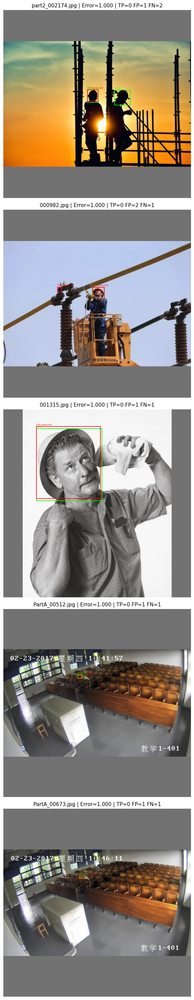

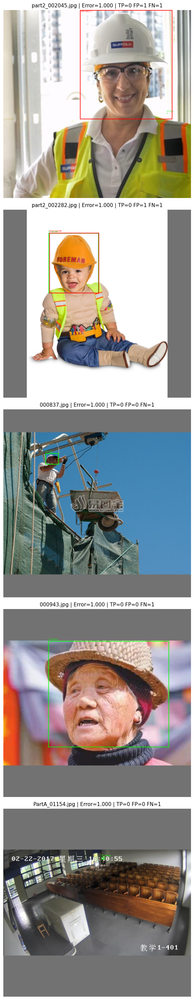

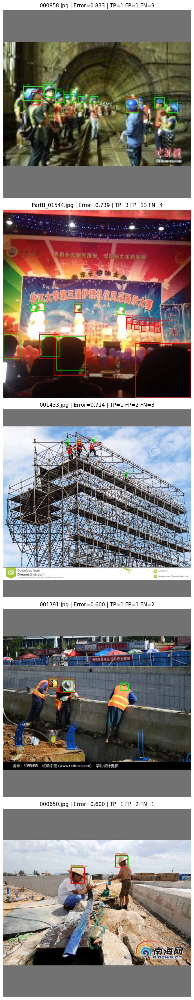

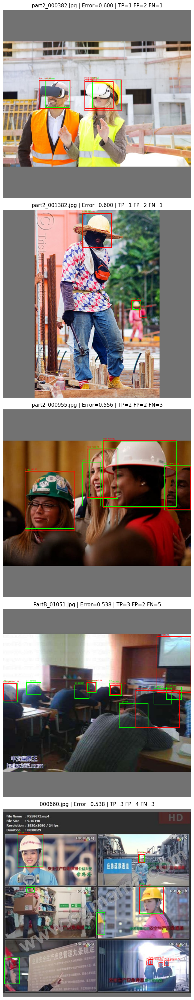

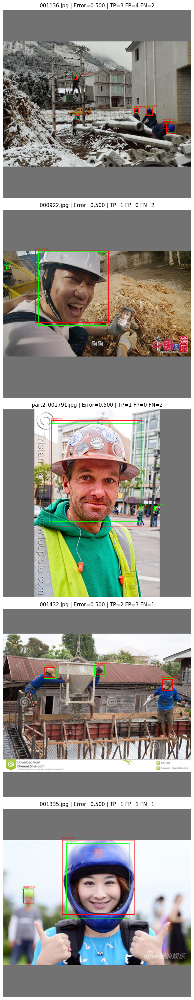

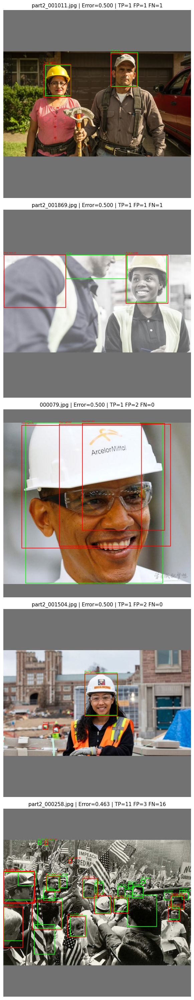

In [19]:

from ultralytics import YOLO
from pathlib import Path
from PIL import Image, ImageDraw
import json
import numpy as np
import pandas as pd
import torch
import gc
import matplotlib.pyplot as plt

# ============================================================
# PATHS
# ============================================================

MODEL_PATH = "/content/drive/MyDrive/SHWD_Experiments/YOLO26m_Contrast_ThinGrid_Online_Fixed/weights/last.pt"

DATASET_PATH = Path("/content/SHWD_Extracted/SHWD_960_Preprocessed")
TEST_IMAGES = DATASET_PATH / "images" / "test"
COCO_PATH = DATASET_PATH / "annotations" / "instances_test.json"

OUTPUT_CSV = "/content/drive/MyDrive/SHWD_Experiments/YOLO26m_ThinGrid_Worst_Cases.csv"

CONF = 0.3
IOU_MATCH = 0.50

# ============================================================
# LOAD MODEL
# ============================================================

model = YOLO(MODEL_PATH)

# ============================================================
# LOAD COCO GROUND TRUTH
# ============================================================

with open(COCO_PATH, "r") as f:
    coco = json.load(f)

# Map category names to YOLO class IDs
name_to_cls = {
    str(name).lower(): int(cls_id)
    for cls_id, name in model.names.items()
}

category_to_cls = {
    cat["id"]: name_to_cls[cat["name"].lower()]
    for cat in coco["categories"]
}

# Map image IDs to filenames, using basename
image_id_to_name = {
    img["id"]: Path(img["file_name"]).name
    for img in coco["images"]
}

# Initialize every image with an empty annotation list
image_annotations = {
    name: [] for name in image_id_to_name.values()
}

# Add ground-truth boxes
for ann in coco["annotations"]:

    image_name = image_id_to_name[ann["image_id"]]

    x, y, w, h = ann["bbox"]
    cls = category_to_cls[ann["category_id"]]

    image_annotations[image_name].append(
        [x, y, x+w, y+h, cls]
    )

# ============================================================
# IMPORTANT: VERIFY ANNOTATION MATCHING
# ============================================================

image_files = sorted(TEST_IMAGES.glob("*"))

matched_files = [
    p for p in image_files
    if p.name in image_annotations
]

missing_files = [
    p.name for p in image_files
    if p.name not in image_annotations
]

total_gt = sum(len(v) for v in image_annotations.values())

print("========== ANNOTATION CHECK ==========")
print("Test images found:", len(image_files))
print("Images matched to COCO:", len(matched_files))
print("Images without COCO entry:", len(missing_files))
print("Total ground-truth objects:", total_gt)
print("Images with at least one object:",
      sum(bool(v) for v in image_annotations.values()))

if len(matched_files) != len(image_files):
    print("Examples of unmatched images:", missing_files[:10])
    raise ValueError("Image-to-COCO filename matching is incomplete!")

if total_gt == 0:
    raise ValueError("No ground-truth annotations found!")

# ============================================================
# IOU FUNCTION
# ============================================================

def calculate_iou(box1, box2):

    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = max(0, x2-x1) * max(0, y2-y1)

    area1 = max(0, box1[2]-box1[0]) * max(0, box1[3]-box1[1])
    area2 = max(0, box2[2]-box2[0]) * max(0, box2[3]-box2[1])

    union = area1 + area2 - intersection

    return intersection / union if union > 0 else 0


# ============================================================
# EVALUATE TEST IMAGES
# ============================================================

records = []

for idx, image_path in enumerate(matched_files):

    prediction = model.predict(
        source=str(image_path),
        imgsz=960,
        conf=CONF,
        iou=0.7,
        device=0,
        verbose=False
    )[0]

    preds = []

    if prediction.boxes is not None:
        for box in prediction.boxes:
            coords = box.xyxy[0].cpu().numpy()
            cls = int(box.cls.item())

            preds.append([*coords, cls])

    gts = image_annotations[image_path.name]

    matched_gt = set()
    TP = 0
    FP = 0

    # Greedy one-to-one matching, same-class boxes only
    for pred in preds:

        best_iou = 0
        best_gt = -1

        for j, gt in enumerate(gts):

            if j in matched_gt:
                continue

            if pred[4] != gt[4]:
                continue

            iou = calculate_iou(pred[:4], gt[:4])

            if iou > best_iou:
                best_iou = iou
                best_gt = j

        if best_iou >= IOU_MATCH:
            TP += 1
            matched_gt.add(best_gt)
        else:
            FP += 1

    FN = len(gts) - TP

    denominator = 2*TP + FP + FN
    error = (FP + FN) / denominator if denominator else 0

    records.append({
        "image": image_path.name,
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "GT": len(gts),
        "Predictions": len(preds),
        "Error": error
    })

    if (idx+1) % 100 == 0:
        print(f"Processed {idx+1}/{len(matched_files)}")

    del prediction

    if (idx+1) % 100 == 0:
        gc.collect()
        torch.cuda.empty_cache()

# ============================================================
# RANK WORST CASES
# ============================================================

df = pd.DataFrame(records)

df = df.sort_values(
    ["Error", "FN", "FP"],
    ascending=False
).reset_index(drop=True)

print("\n========== 30 WORST CASES ==========")
display(df.head(30))

df.to_csv(OUTPUT_CSV, index=False)
print("Saved:", OUTPUT_CSV)

# ============================================================
# VISUALIZE 30 WORST CASES
# ============================================================

worst_30 = df.head(30)

for start in range(0, len(worst_30), 5):

    batch = worst_30.iloc[start:start+5]

    fig, axes = plt.subplots(
        len(batch), 1,
        figsize=(14, 6*len(batch))
    )

    if len(batch) == 1:
        axes = [axes]

    for ax, (_, row) in zip(axes, batch.iterrows()):

        image_path = TEST_IMAGES / row["image"]

        img = Image.open(image_path).convert("RGB")
        draw = ImageDraw.Draw(img)

        # Ground truth boxes: GREEN
        for gt in image_annotations[row["image"]]:

            x1, y1, x2, y2, cls = gt

            draw.rectangle(
                [x1, y1, x2, y2],
                outline="lime",
                width=3
            )

            draw.text(
                (x1, max(0, y1-15)),
                f"GT: {model.names[int(cls)]}",
                fill="lime"
            )

        # Predictions: RED
        pred_result = model.predict(
            source=str(image_path),
            imgsz=960,
            conf=CONF,
            iou=0.7,
            device=0,
            verbose=False
        )[0]

        for box in pred_result.boxes:

            coords = box.xyxy[0].cpu().numpy()
            cls = int(box.cls.item())
            conf = float(box.conf.item())

            draw.rectangle(
                list(coords),
                outline="red",
                width=3
            )

            draw.text(
                (coords[0], max(0, coords[1]-15)),
                f"Pred: {model.names[cls]} {conf:.2f}",
                fill="red"
            )

        ax.imshow(img)
        ax.axis("off")

        ax.set_title(
            f"{row['image']} | Error={row['Error']:.3f} | "
            f"TP={row['TP']} FP={row['FP']} FN={row['FN']}",
            fontsize=11
        )

        del pred_result, img

    plt.tight_layout()
    plt.show()

    del fig, axes
    gc.collect()
    torch.cuda.empty_cache()


#1 Contrast (Partial)
#2 Extra image detected
#3 Occlusion (Previosly had Contrast error)
#4 No error
#5 No error
#6 No error (Problem with ground truth)
#7 Soft hat
#8 Occlusion
#9 Large object
#10 Low visibility
#11 Blur
#12 Background Photos
#13 Occlusion
#14 Occlusion
#15 Soft hats
#16 Other objects
#17 Soft hats
#18 Overlapping objects
#19 Low Visibility
#20 Occlusion + Imperfect Ground truth
#21 Classification error
#22 Imperfect Ground Truth
#23 Low Visibility
#24 Soft Hats
#25 Incorrect Ground Truth
#26 Soft hats
#27 Occlusion
#28 Single object detected multiple times
#29 Incorrect Ground Truth
#30 Contrast (Partial)

In [16]:
import shutil
from pathlib import Path

# Source checkpoint
source = Path(
    "/content/drive/MyDrive/SHWD_Experiments/"
    "YOLO26m_Contrast_ThinGrid_Online_Fixed/weights/last.pt"
)

# Destination on Google Drive
destination = Path(
    "/content/drive/MyDrive/SHWD_Experiments/"
    "YOLO26m_Contrast_ThinGrid_Online_Fixed_last.pt"
)

if source.exists():
    shutil.copy2(source, destination)
    print(f"Successfully saved: {destination}")
    print(f"File size: {destination.stat().st_size / (1024**2):.2f} MB")
else:
    print(f"ERROR: Checkpoint not found at {source}")

Successfully saved: /content/drive/MyDrive/SHWD_Experiments/YOLO26m_Contrast_ThinGrid_Online_Fixed_last.pt
File size: 208.56 MB


In [18]:
import torch
import pandas as pd
import numpy as np
from pathlib import Path
from collections import defaultdict
from ultralytics import YOLO
from tqdm.auto import tqdm

# ============================================================
# 1. PATHS AND SETTINGS
# ============================================================

MODEL_PATH = "/content/drive/MyDrive/SHWD_Experiments/YOLO26m_Contrast_ThinGrid_Online_Fixed_last.pt"

ROOT = Path("/content/SHWD_Extracted/SHWD_960_Preprocessed")
TEST_IMAGES = ROOT / "images/test"
COCO_JSON = ROOT / "annotations/instances_test.json"

IOU_THRESHOLD = 0.5
CONF_THRESHOLDS = [0.05, 0.10, 0.15, 0.20, 0.25,
                   0.30, 0.35, 0.40, 0.45, 0.50,
                   0.55, 0.60, 0.65, 0.70, 0.75,
                   0.80, 0.85, 0.90, 0.95]

# ============================================================
# 2. LOAD MODEL
# ============================================================

model = YOLO(MODEL_PATH)

print("Model loaded:", MODEL_PATH)
print("Classes:", model.names)

# ============================================================
# 3. LOAD GROUND-TRUTH ANNOTATIONS
# ============================================================

import json

with open(COCO_JSON, "r") as f:
    coco = json.load(f)

image_id_to_name = {
    img["id"]: Path(img["file_name"]).name
    for img in coco["images"]
}

category_id_to_name = {
    cat["id"]: cat["name"]
    for cat in coco["categories"]
}

class_name_to_id = {
    name: int(class_id)
    for class_id, name in model.names.items()
}

image_annotations = defaultdict(list)

for ann in coco["annotations"]:
    image_name = image_id_to_name[ann["image_id"]]
    class_name = category_id_to_name[ann["category_id"]]

    if class_name not in class_name_to_id:
        continue

    x, y, w, h = ann["bbox"]

    image_annotations[image_name].append({
        "class_id": class_name_to_id[class_name],
        "box": [x, y, x + w, y + h]
    })

image_files = sorted([
    p for p in TEST_IMAGES.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
])

total_gt = sum(len(v) for v in image_annotations.values())

print("\nTest images:", len(image_files))
print("Images with annotations:", sum(
    1 for p in image_files if p.name in image_annotations
))
print("Total ground-truth objects:", total_gt)
print("Ground truth by class:")

for name, class_id in class_name_to_id.items():
    count = sum(
        1 for anns in image_annotations.values()
        for ann in anns if ann["class_id"] == class_id
    )
    print(f"  {name}: {count}")

assert total_gt > 0, "No ground-truth annotations matched. Check COCO file paths."
assert len(image_files) > 0, "No test images found."

# ============================================================
# 4. IOU FUNCTION
# ============================================================

def calculate_iou(box1, box2):
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = max(0, x2 - x1) * max(0, y2 - y1)

    area1 = max(0, box1[2] - box1[0]) * max(0, box1[3] - box1[1])
    area2 = max(0, box2[2] - box2[0]) * max(0, box2[3] - box2[1])

    union = area1 + area2 - intersection

    return intersection / union if union > 0 else 0


# ============================================================
# 5. STORE PREDICTIONS ONCE PER IMAGE
# ============================================================

predictions = {}

for image_path in tqdm(image_files, desc="Running inference"):

    result = model.predict(
        source=str(image_path),
        imgsz=960,
        conf=0.001,       # Low threshold so we can evaluate many thresholds later
        iou=0.7,          # NMS IoU threshold; separate from evaluation IoU
        device=0,
        verbose=False
    )[0]

    image_predictions = []

    if result.boxes is not None:
        for box in result.boxes:
            image_predictions.append({
                "class_id": int(box.cls.item()),
                "confidence": float(box.conf.item()),
                "box": box.xyxy[0].cpu().tolist()
            })

    predictions[image_path.name] = image_predictions

print("Inference completed.")

# ============================================================
# 6. EVALUATE EACH CONFIDENCE THRESHOLD
# ============================================================

rows = []

for threshold in tqdm(CONF_THRESHOLDS, desc="Evaluating thresholds"):

    stats = {
        class_name: {"TP": 0, "FP": 0, "FN": 0}
        for class_name in class_name_to_id
    }

    for image_path in image_files:

        image_name = image_path.name
        gt_objects = image_annotations.get(image_name, [])
        pred_objects = [
            p for p in predictions.get(image_name, [])
            if p["confidence"] >= threshold
        ]

        # Match separately for each class
        for class_name, class_id in class_name_to_id.items():

            gt_class = [
                g for g in gt_objects
                if g["class_id"] == class_id
            ]

            pred_class = [
                p for p in pred_objects
                if p["class_id"] == class_id
            ]

            # Highest-confidence predictions first
            pred_class.sort(
                key=lambda p: p["confidence"],
                reverse=True
            )

            matched_gt = set()

            for pred in pred_class:

                best_iou = 0
                best_gt_index = None

                for gt_index, gt in enumerate(gt_class):

                    if gt_index in matched_gt:
                        continue

                    iou = calculate_iou(pred["box"], gt["box"])

                    if iou > best_iou:
                        best_iou = iou
                        best_gt_index = gt_index

                if best_iou >= IOU_THRESHOLD:
                    stats[class_name]["TP"] += 1
                    matched_gt.add(best_gt_index)
                else:
                    stats[class_name]["FP"] += 1

            stats[class_name]["FN"] += (
                len(gt_class) - len(matched_gt)
            )

    # Save class-wise results
    for class_name in class_name_to_id:

        TP = stats[class_name]["TP"]
        FP = stats[class_name]["FP"]
        FN = stats[class_name]["FN"]

        precision = TP / (TP + FP) if TP + FP else 0
        recall = TP / (TP + FN) if TP + FN else 0

        rows.append({
            "Confidence": threshold,
            "Class": class_name,
            "Precision": precision,
            "Recall": recall,
            "TP": TP,
            "FP": FP,
            "FN": FN
        })

# ============================================================
# 7. DISPLAY AND SAVE RESULTS
# ============================================================

df = pd.DataFrame(rows)

print("\nCLASS-WISE PRECISION AND RECALL")
display(
    df[["Confidence", "Class", "Precision", "Recall"]]
    .round(4)
)

output_path = (
    "/content/drive/MyDrive/SHWD_Experiments/"
    "YOLO26m_Contrast_ThinGrid_PR_Thresholds.csv"
)

df.to_csv(output_path, index=False)

print("\nFull results saved to:", output_path)

Model loaded: /content/drive/MyDrive/SHWD_Experiments/YOLO26m_Contrast_ThinGrid_Online_Fixed_last.pt
Classes: {0: 'hat', 1: 'person'}

Test images: 1517
Images with annotations: 1517
Total ground-truth objects: 24436
Ground truth by class:
  hat: 1878
  person: 22558


Running inference:   0%|          | 0/1517 [00:00<?, ?it/s]

Inference completed.


Evaluating thresholds:   0%|          | 0/19 [00:00<?, ?it/s]


CLASS-WISE PRECISION AND RECALL


,Confidence,Class,Precision,Recall
0,0.05,hat,0.7423,0.9542
1,0.05,person,0.7125,0.9718
2,0.10,hat,0.8200,0.9462
3,0.10,person,0.7994,0.9646
4,0.15,hat,0.8621,0.9388
5,0.15,person,0.8439,0.9593
6,0.20,hat,0.8859,0.9302
7,0.20,person,0.8734,0.9533
8,0.25,hat,0.9041,0.9239
9,0.25,person,0.8947,0.9480



Full results saved to: /content/drive/MyDrive/SHWD_Experiments/YOLO26m_Contrast_ThinGrid_PR_Thresholds.csv


Precision and Recall at multiple thresholds
# The objective is to mainly maximise recall of "Person", and also to maximise the precision of "Hat" while maintaining good F-1 scores
# While 0.3,0.35 and 0.4 are potential candidates 0.3 is what I choose as it has a good recall for "Person" while also having a 0.91+ scores for all other (P and R)

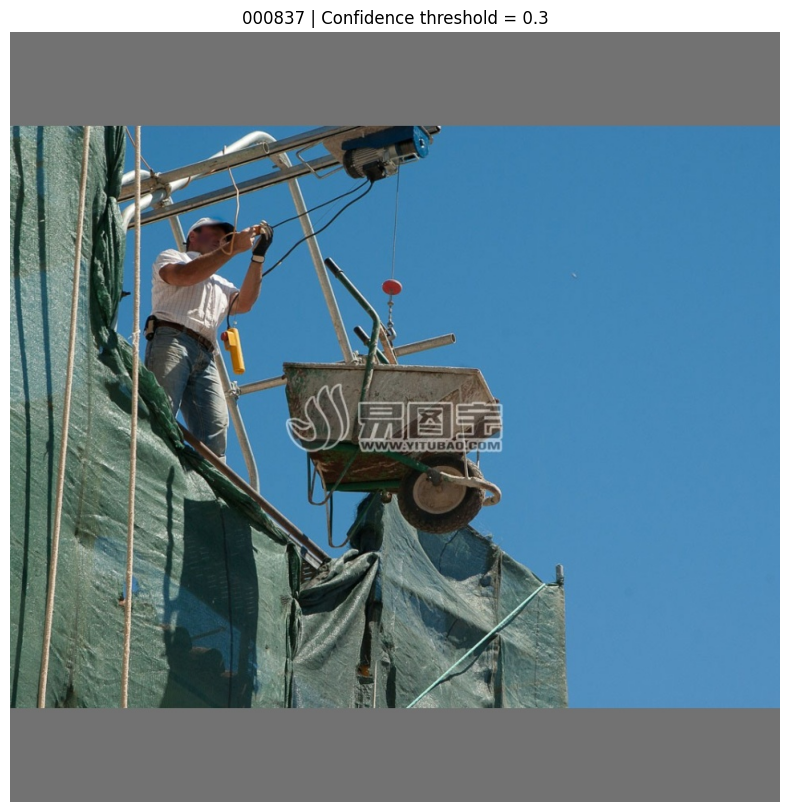


Image: 000837
No detections.


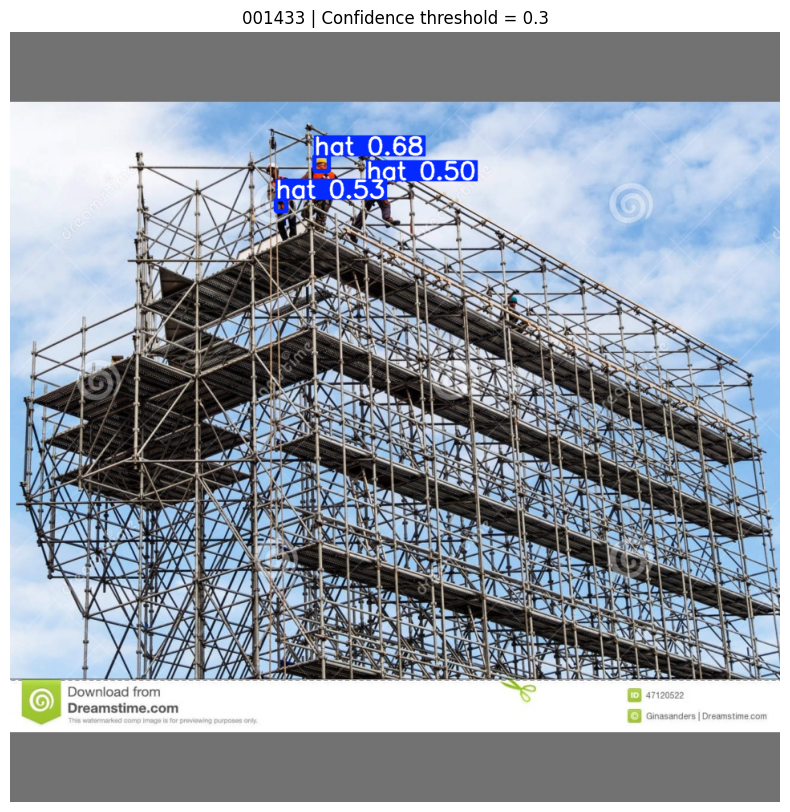


Image: 001433
hat      | Confidence: 0.6777 | Box: [379.2, 154.0, 397.3, 173.8]
hat      | Confidence: 0.5348 | Box: [331.2, 208.1, 344.6, 223.5]
hat      | Confidence: 0.4951 | Box: [444.9, 185.1, 459.5, 201.7]
Total detections: 3


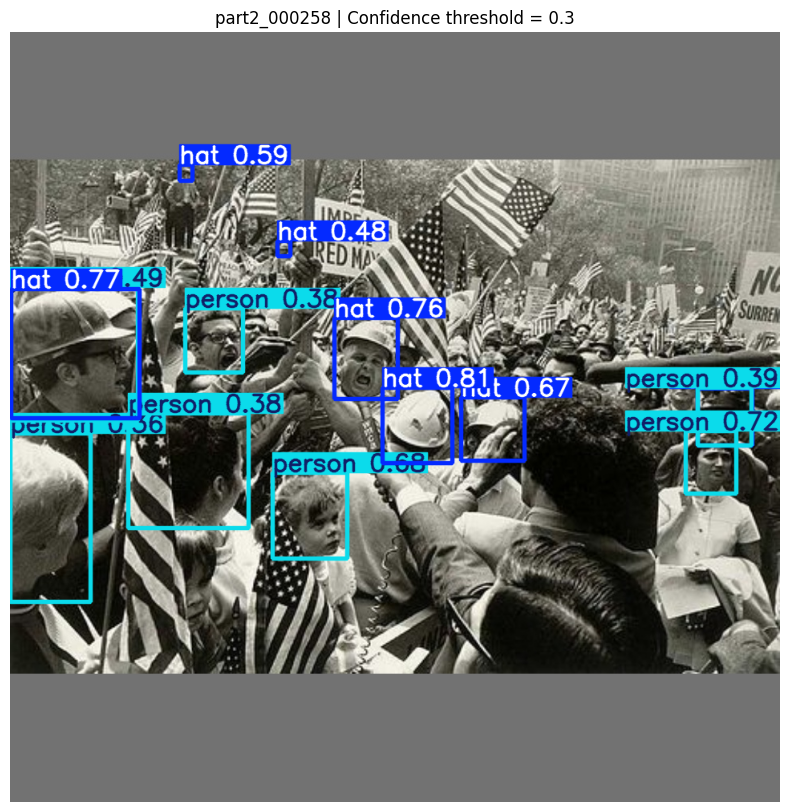


Image: part2_000258
hat      | Confidence: 0.8054 | Box: [464.8, 444.0, 551.8, 537.8]
hat      | Confidence: 0.7746 | Box: [1.5, 320.1, 161.2, 481.3]
hat      | Confidence: 0.7618 | Box: [404.1, 356.9, 483.2, 457.6]
person   | Confidence: 0.7197 | Box: [842.1, 497.5, 905.7, 575.6]
person   | Confidence: 0.6789 | Box: [327.8, 549.2, 420.1, 656.1]
hat      | Confidence: 0.6711 | Box: [562.4, 455.5, 641.9, 534.9]
hat      | Confidence: 0.5933 | Box: [211.5, 165.6, 227.3, 185.4]
person   | Confidence: 0.4894 | Box: [0.9, 318.8, 160.0, 484.4]
hat      | Confidence: 0.4830 | Box: [333.1, 260.0, 349.6, 279.9]
person   | Confidence: 0.3858 | Box: [858.0, 443.8, 924.7, 515.4]
person   | Confidence: 0.3834 | Box: [147.3, 475.1, 297.5, 618.8]
person   | Confidence: 0.3811 | Box: [218.1, 344.2, 290.3, 424.2]
person   | Confidence: 0.3555 | Box: [0.0, 500.2, 100.2, 710.2]
hat      | Confidence: 0.3369 | Box: [857.7, 444.1, 925.2, 515.4]
Total detections: 14
Image not found: partB_02193


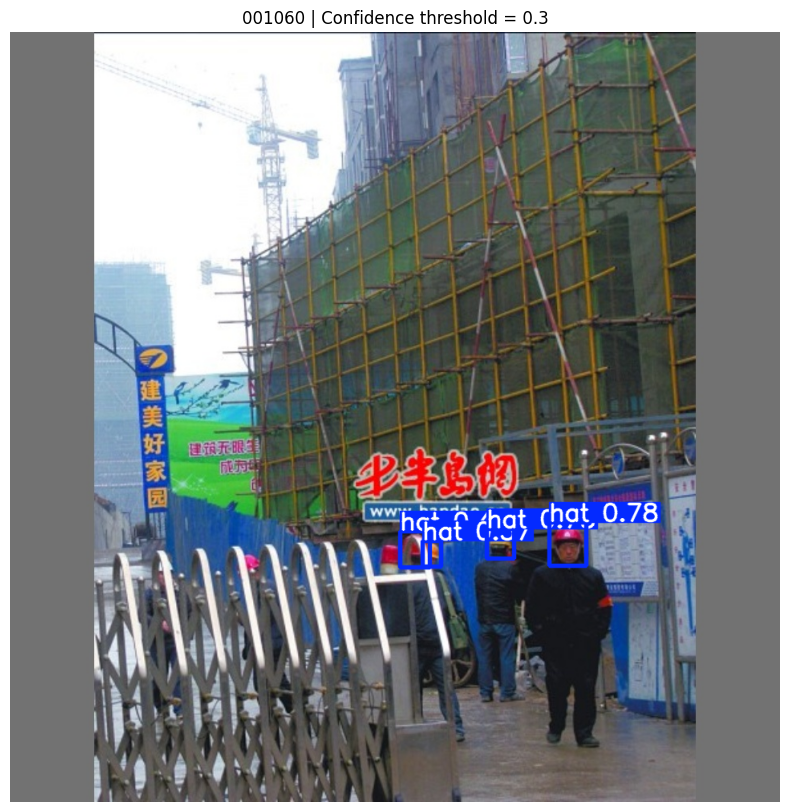


Image: 001060
hat      | Confidence: 0.7825 | Box: [672.9, 612.0, 718.5, 665.2]
hat      | Confidence: 0.7549 | Box: [594.6, 619.1, 628.3, 656.3]
hat      | Confidence: 0.5675 | Box: [514.3, 634.1, 537.8, 666.4]
hat      | Confidence: 0.4824 | Box: [486.3, 622.4, 523.4, 667.5]
Total detections: 4


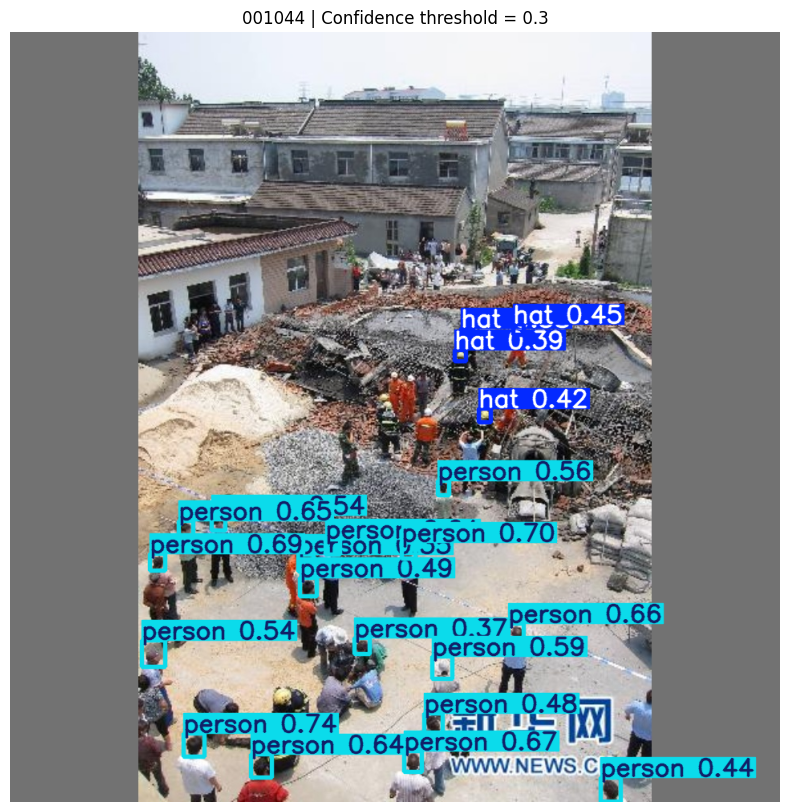


Image: 001044
person   | Confidence: 0.7445 | Box: [216.5, 875.0, 242.9, 903.8]
person   | Confidence: 0.7012 | Box: [488.1, 636.3, 505.6, 656.6]
person   | Confidence: 0.6898 | Box: [174.7, 650.2, 193.8, 671.2]
person   | Confidence: 0.6684 | Box: [491.2, 896.8, 513.9, 923.0]
person   | Confidence: 0.6571 | Box: [621.4, 737.8, 640.8, 758.4]
person   | Confidence: 0.6489 | Box: [210.2, 609.1, 228.6, 628.9]
person   | Confidence: 0.6403 | Box: [300.1, 900.9, 326.9, 929.8]
person   | Confidence: 0.6372 | Box: [393.3, 632.2, 411.6, 651.3]
person   | Confidence: 0.5871 | Box: [526.8, 778.6, 551.5, 806.2]
person   | Confidence: 0.5590 | Box: [533.5, 560.0, 547.6, 577.0]
person   | Confidence: 0.5442 | Box: [164.5, 758.7, 193.3, 791.2]
person   | Confidence: 0.5370 | Box: [251.2, 602.1, 268.3, 621.4]
person   | Confidence: 0.4899 | Box: [361.2, 680.6, 382.0, 703.6]
person   | Confidence: 0.4839 | Box: [516.0, 849.8, 539.7, 874.7]
hat      | Confidence: 0.4548 | Box: [627.6, 364.2, 640.1, 37

In [28]:
from ultralytics import YOLO
from pathlib import Path
import matplotlib.pyplot as plt

# ============================================================
# 1. LOAD MODEL
# ============================================================

MODEL_PATH = "/content/drive/MyDrive/SHWD_Experiments/YOLO26m_Contrast_ThinGrid_Online_Fixed_last.pt"

model = YOLO(MODEL_PATH)

# ============================================================
# 2. SETTINGS
# ============================================================

TEST_DIR = Path("/content/SHWD_Extracted/SHWD_960_Preprocessed/images/test")

IMAGE_IDS = [
    "000837",
    "001433",
    "part2_000258",
    "partB_02193",
    "001060",
    "001044"
]

CONF_THRESHOLD = 0.3
IOU_THRESHOLD = 0.7

# ============================================================
# 3. FIND AND TEST IMAGES
# ============================================================

for image_id in IMAGE_IDS:

    matches = list(TEST_DIR.glob(image_id + ".*"))

    if not matches:
        print(f"Image not found: {image_id}")
        continue

    image_path = matches[0]

    results = model.predict(
        source=str(image_path),
        imgsz=960,
        conf=CONF_THRESHOLD,
        iou=IOU_THRESHOLD,
        device=0,
        verbose=False
    )

    result = results[0]

    # Plot predictions
    plotted_image = result.plot()

    plt.figure(figsize=(10, 10))
    plt.imshow(plotted_image[:, :, ::-1])
    plt.title(f"{image_id} | Confidence threshold = {CONF_THRESHOLD}")
    plt.axis("off")
    plt.show()

    # Print individual detections
    print(f"\nImage: {image_id}")

    if result.boxes is None or len(result.boxes) == 0:
        print("No detections.")
        continue

    for box in result.boxes:
        class_id = int(box.cls.item())
        class_name = model.names[class_id]
        confidence = float(box.conf.item())
        coordinates = box.xyxy[0].cpu().tolist()

        print(
            f"{class_name:8s} | "
            f"Confidence: {confidence:.4f} | "
            f"Box: {[round(x, 1) for x in coordinates]}"
        )

    print("Total detections:", len(result.boxes))

Checking images where occlusion or contrast  was the reason for failure previously

#Inference:-The new Thin-Line Augmentation failed to make any substantial improvement in cases where occlusion was the reason for the failure,
# whereas the contrast-specific augmentations were partially able to remove errors due to Contrast as we notice in the 30 top errors
#Conclusion:- Fix worked partially, but I wouldnt consider it success